In [2]:
from google.colab import files
uploaded = files.upload()

Saving 12573233-Indian_Car_Market_Capstone_2025_Dataset.zip to 12573233-Indian_Car_Market_Capstone_2025_Dataset.zip


In [3]:
import zipfile
import os

zip_path = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

extract_folder = "/content/car_dataset"
os.makedirs(extract_folder, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_folder)

print("Extracted files:")
for filename in os.listdir(extract_folder):
    print(filename)

Extracted files:
Cap_Test_Data_2025.csv
Cap_Training_Data_2025.csv
Cap_Sample_Submission_2025.csv


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_path = os.path.join(
    extract_folder, "Cap_Training_Data_2025.csv"
)
test_path = os.path.join(
    extract_folder, "Cap_Test_Data_2025.csv"
)
submission_path = os.path.join(
    extract_folder, "Cap_Sample_Submission_2025.csv"
)

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
sample_submission = pd.read_csv(submission_path)

print("Training dataset shape:", train_df.shape)
print("Test dataset shape:", test_df.shape)
print("Sample submission shape:", sample_submission.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

display(train_df.head())

Training dataset shape: (53515, 17)
Test dataset shape: (5615, 16)
Sample submission shape: (5615, 2)

Training columns:
['ID', 'Maker', 'model', 'Location', 'Distance ', 'Owner Type', 'manufacture_year', 'Age of car', 'engine_displacement', 'engine_power', 'body_type', 'Vroom Audit Rating', 'transmission', 'door_count', 'seat_count', 'fuel_type', 'Price']


,ID,Maker,model,Location,Distance,Owner Type,manufacture_year,Age of car,engine_displacement,engine_power,body_type,Vroom Audit Rating,transmission,door_count,seat_count,fuel_type,Price
0,11100001,skoda,octavia,Ahmedabad,NaN,Second,1973.0,52,1964,147.0,compact,8,man,NaN,NaN,petrol,543764.25
1,11100002,fiat,panda,Ahmedabad,27750.0,Third,2021.0,4,1242,51.0,NaN,6,man,4.0,4.0,petrol,401819.25
2,11100003,bmw,x1,Hyderabad,46000.0,Third,2023.0,2,1995,105.0,NaN,7,auto,4.0,5.0,diesel,2392855.50
3,11100004,nissan,juke,Mumbai,43949.0,Third,2020.0,5,1618,140.0,NaN,7,man,4.0,5.0,petrol,958606.50
4,11100005,bmw,x5,Jaipur,59524.0,Fourth & Above,2021.0,4,2993,180.0,NaN,7,auto,4.0,5.0,diesel,3085561.50


In [5]:
# Remove leading/trailing spaces from column names
train_df.columns = train_df.columns.str.strip()
test_df.columns = test_df.columns.str.strip()
sample_submission.columns = sample_submission.columns.str.strip()

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nMissing values in training data:")
display(
    train_df.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Count")
)

print("\nData types:")
display(train_df.dtypes.to_frame("Data Type"))

print("\nStatistical summary:")
display(train_df.describe(include="all").T)

Training shape: (53515, 17)
Test shape: (5615, 16)

Missing values in training data:


,Missing Count
body_type,49379
seat_count,8511
door_count,7534
engine_power,1439
Distance,1211
Location,6
manufacture_year,2
ID,0
model,0
engine_displacement,0



Data types:


,Data Type
ID,int64
Maker,object
model,object
Location,object
Distance,float64
Owner Type,object
manufacture_year,float64
Age of car,int64
engine_displacement,int64
engine_power,float64



Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,53515.0,NaN,NaN,NaN,11126758.0,15448.594165,11100001.0,11113379.5,11126758.0,11140136.5,11153515.0
Maker,53515,8,skoda,21563,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,53515,23,octavia,12619,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,53509,11,Coimbatore,4974,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Distance,52304.0,NaN,NaN,NaN,94546.262446,275561.716141,0.0,15490.0,65520.0,135641.0,9899800.0
Owner Type,53515,4,First,13406,NaN,NaN,NaN,NaN,NaN,NaN,NaN
manufacture_year,53513.0,NaN,NaN,NaN,2019.408032,4.650367,1943.0,2017.0,2020.0,2023.0,2025.0
Age of car,53515.0,NaN,NaN,NaN,5.591946,4.650281,0.0,2.0,5.0,8.0,82.0
engine_displacement,53515.0,NaN,NaN,NaN,1904.049014,1496.564596,14.0,1395.0,1896.0,1995.0,32000.0
engine_power,52076.0,NaN,NaN,NaN,100.448345,45.330622,10.0,73.0,91.0,125.0,896.0


Price summary:


,Price
count,5.351500e+04
mean,1.098084e+06
std,8.441565e+05
min,3.000000e+00
25%,5.051812e+05
50%,8.854552e+05
75%,1.477829e+06
max,2.212078e+07


Missing prices: 0
Non-positive prices: 0


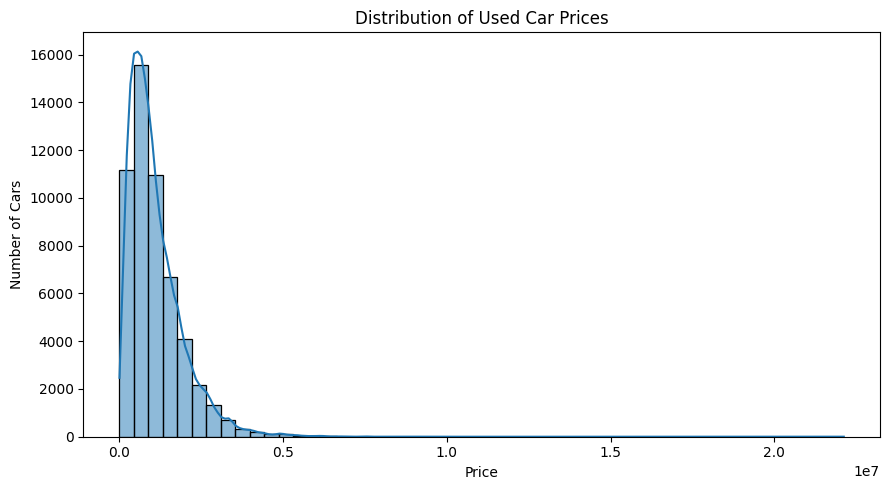

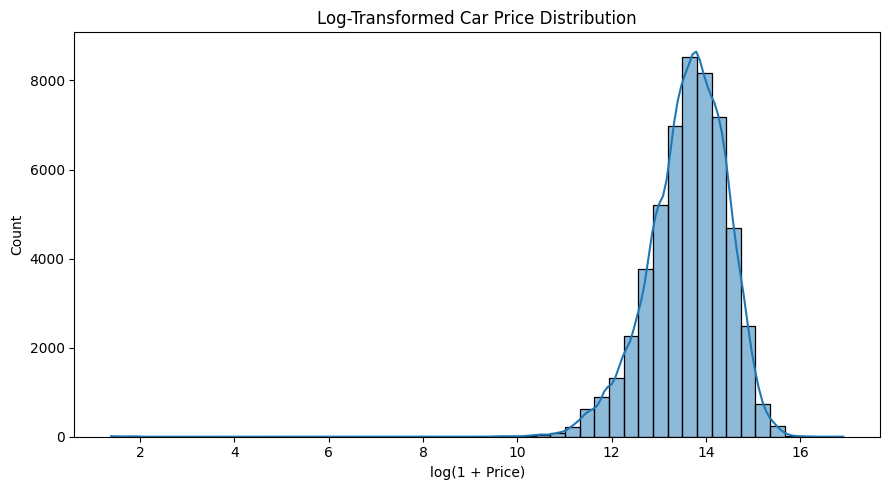

In [6]:
print("Price summary:")
display(train_df["Price"].describe())

print("Missing prices:", train_df["Price"].isnull().sum())
print("Non-positive prices:", (train_df["Price"] <= 0).sum())

plt.figure(figsize=(9, 5))
sns.histplot(train_df["Price"].dropna(), bins=50, kde=True)
plt.title("Distribution of Used Car Prices")
plt.xlabel("Price")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.histplot(
    np.log1p(train_df.loc[train_df["Price"] > 0, "Price"]),
    bins=50, kde=True
)
plt.title("Log-Transformed Car Price Distribution")
plt.xlabel("log(1 + Price)")
plt.tight_layout()
plt.show()

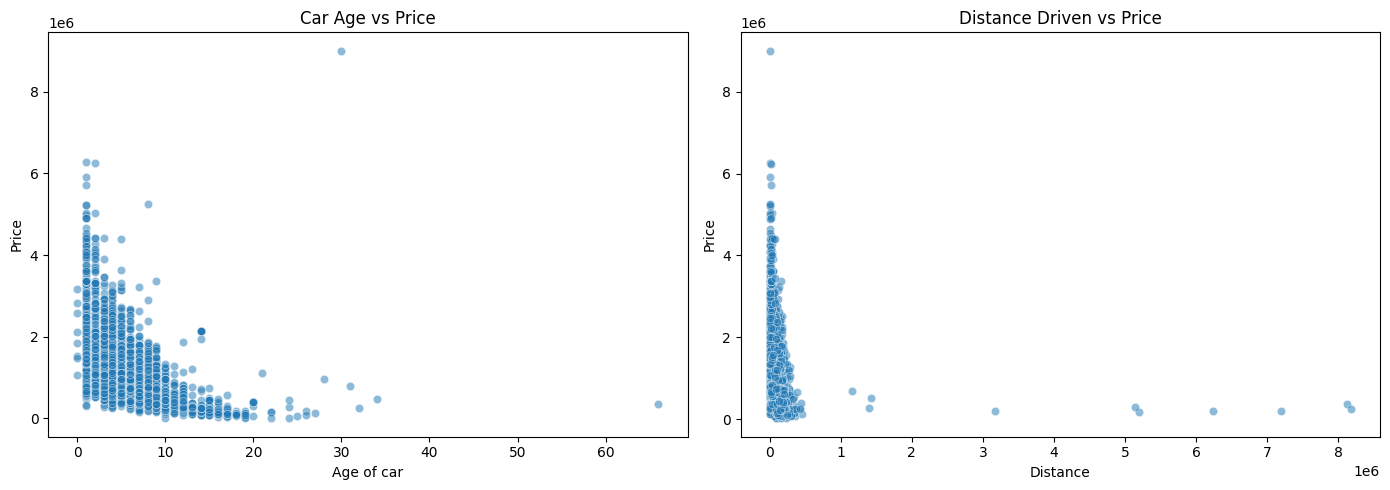

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=train_df.sample(min(3000, len(train_df)), random_state=42),
    x="Age of car", y="Price", alpha=0.5, ax=axes[0]
)
axes[0].set_title("Car Age vs Price")

sns.scatterplot(
    data=train_df.sample(min(3000, len(train_df)), random_state=42),
    x="Distance", y="Price", alpha=0.5, ax=axes[1]
)
axes[1].set_title("Distance Driven vs Price")

plt.tight_layout()
plt.show()

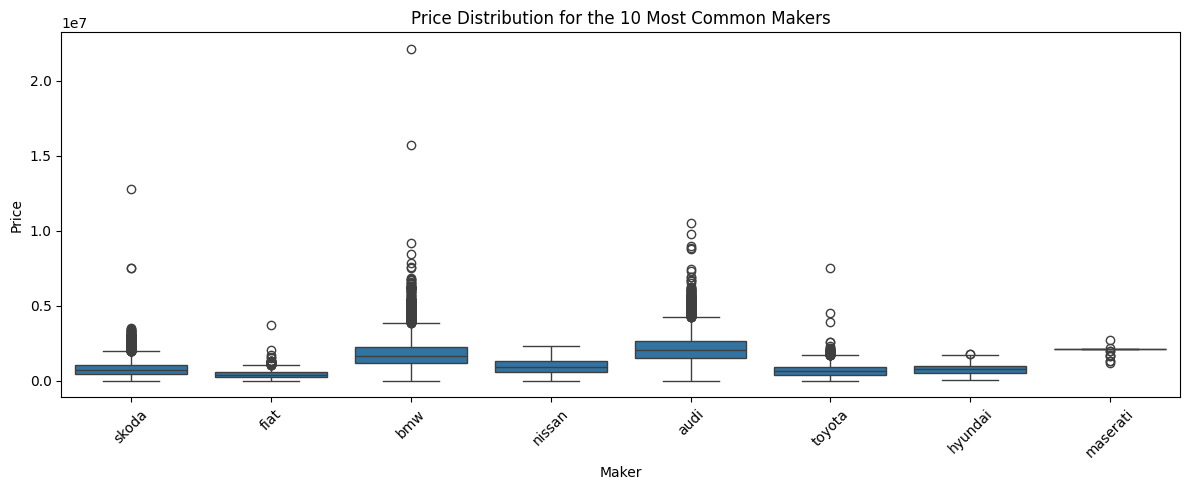

In [8]:
top_makers = train_df["Maker"].value_counts().head(10).index

plt.figure(figsize=(12, 5))
sns.boxplot(
    data=train_df[train_df["Maker"].isin(top_makers)],
    x="Maker", y="Price"
)
plt.title("Price Distribution for the 10 Most Common Makers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Create copies so the original datasets remain unchanged.
train_clean = train_df.copy()
test_clean = test_df.copy()

# Validate target rows.
train_clean = train_clean[
    train_clean["Price"].notna() &
    (train_clean["Price"] > 0)
].copy()

# Drop ID from model features; preserve it for submission.
target = "Price"
id_column = "ID"

X = train_clean.drop(columns=[target, id_column])
y = train_clean[target]

X_test = test_clean.drop(columns=[id_column])

# Align test columns to the training feature columns.
X_test = X_test.reindex(columns=X.columns)

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training split:", X_train.shape)
print("Validation split:", X_valid.shape)

Numeric features: ['Distance', 'manufacture_year', 'Age of car', 'engine_displacement', 'engine_power', 'Vroom Audit Rating', 'door_count', 'seat_count']
Categorical features: ['Maker', 'model', 'Location', 'Owner Type', 'body_type', 'transmission', 'fuel_type']
Training split: (42812, 15)
Validation split: (10703, 15)


In [10]:

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np
import time

# Define the models to compare
models = {
    "Median Baseline": DummyRegressor(strategy="median"),
    "Ridge Regression": Ridge(alpha=10),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, estimator in models.items():
    print(f"\nTraining {name}...")
    start_time = time.time()

    # Preprocessing is fitted only on the training split to avoid data leakage
    model_pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", estimator)
    ])

    model_pipeline.fit(X_train, y_train)
    predictions = model_pipeline.predict(X_valid)

    rmse = np.sqrt(mean_squared_error(y_valid, predictions))
    mae = mean_absolute_error(y_valid, predictions)
    r2 = r2_score(y_valid, predictions)

    results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2,
        "Training Time (seconds)": round(time.time() - start_time, 2)
    })

    trained_models[name] = model_pipeline

    print(f"RMSE: {rmse:,.2f}")
    print(f"MAE:  {mae:,.2f}")
    print(f"R²:   {r2:.4f}")

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df)



Training Median Baseline...
RMSE: 872,322.59
MAE:  603,668.66
R²:   -0.0692

Training Ridge Regression...
RMSE: 430,598.48
MAE:  263,388.95
R²:   0.7395

Training Random Forest...
RMSE: 199,960.70
MAE:  106,908.42
R²:   0.9438


,Model,RMSE,MAE,R2 Score,Training Time (seconds)
2,Random Forest,199960.695139,106908.417069,0.943816,122.09
1,Ridge Regression,430598.478112,263388.947796,0.739463,0.63
0,Median Baseline,872322.587313,603668.655237,-0.069248,0.65


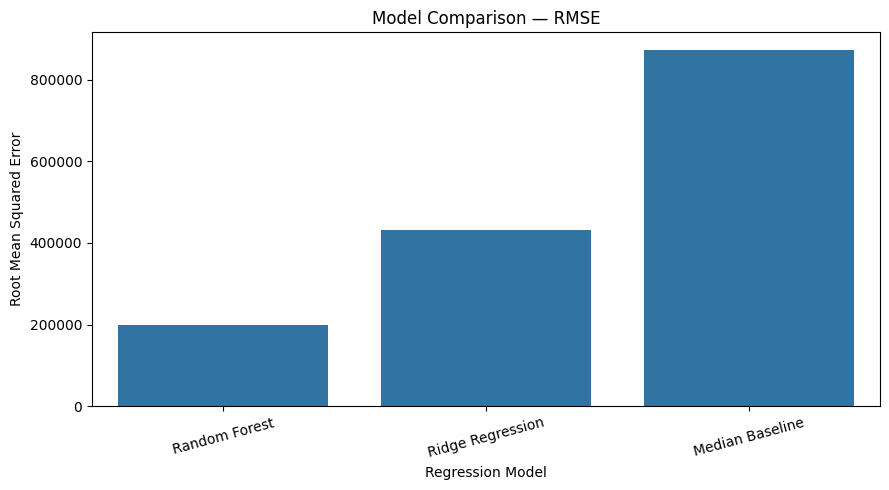

In [11]:

plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="RMSE")
plt.title("Model Comparison — RMSE")
plt.ylabel("Root Mean Squared Error")
plt.xlabel("Regression Model")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


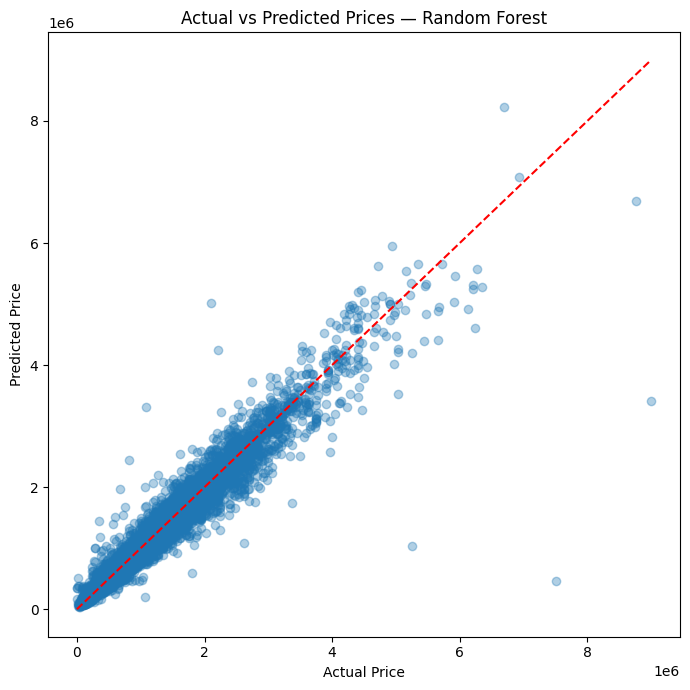

Best model by validation RMSE: Random Forest


In [12]:

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

valid_predictions = best_model.predict(X_valid)

plt.figure(figsize=(7, 7))
plt.scatter(y_valid, valid_predictions, alpha=0.35)
lower = min(y_valid.min(), valid_predictions.min())
upper = max(y_valid.max(), valid_predictions.max())
plt.plot([lower, upper], [lower, upper], "r--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(f"Actual vs Predicted Prices — {best_model_name}")
plt.tight_layout()
plt.show()

print("Best model by validation RMSE:", best_model_name)


In [13]:

best_row = results_df.iloc[0]

print("BEST VALIDATION MODEL")
print("---------------------")
print("Model:", best_row["Model"])
print(f"RMSE: {best_row['RMSE']:,.2f}")
print(f"MAE:  {best_row['MAE']:,.2f}")
print(f"R² Score: {best_row['R2 Score']:.4f}")


BEST VALIDATION MODEL
---------------------
Model: Random Forest
RMSE: 199,960.70
MAE:  106,908.42
R² Score: 0.9438


In [15]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_squared_error
import numpy as np
import time

# Use a smaller subset for quick model selection
X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=min(10000, len(X_train)),
    random_state=42
)

# Use one validation split instead of 3-fold cross-validation
X_fit, X_check, y_fit, y_check = train_test_split(
    X_tune, y_tune, test_size=0.20, random_state=42
)

settings = [
    {"n_estimators": 50, "max_depth": 15},
    {"n_estimators": 75, "max_depth": 25}
]

quick_results = []
quick_models = []

for params in settings:
    print("Testing:", params)
    start = time.time()

    pipe = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            **params,
            min_samples_leaf=2,
            max_features=0.8,
            random_state=42,
            n_jobs=-1
        ))
    ])

    pipe.fit(X_fit, y_fit)
    pred = pipe.predict(X_check)
    rmse = np.sqrt(mean_squared_error(y_check, pred))

    quick_results.append({
        "Parameters": str(params),
        "RMSE": rmse,
        "Time (seconds)": round(time.time() - start, 1)
    })
    quick_models.append(pipe)

quick_results_df = pd.DataFrame(quick_results).sort_values("RMSE")
display(quick_results_df)

best_quick_index = quick_results_df.index[0]
tuned_model = quick_models[best_quick_index]
print("Fast tuning completed.")


Testing: {'n_estimators': 50, 'max_depth': 15}
Testing: {'n_estimators': 75, 'max_depth': 25}


,Parameters,RMSE,Time (seconds)
1,"{'n_estimators': 75, 'max_depth': 25}",204825.285721,8.4
0,"{'n_estimators': 50, 'max_depth': 15}",206255.812423,4.8


Fast tuning completed.


In [17]:

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

tuned_predictions = tuned_model.predict(X_valid)

tuned_rmse = np.sqrt(mean_squared_error(y_valid, tuned_predictions))
tuned_mae = mean_absolute_error(y_valid, tuned_predictions)
tuned_r2 = r2_score(y_valid, tuned_predictions)

print("TUNED MODEL — VALIDATION RESULTS")
print("--------------------------------")
print(f"RMSE: {tuned_rmse:,.2f}")
print(f"MAE:  {tuned_mae:,.2f}")
print(f"R² Score: {tuned_r2:.4f}")


TUNED MODEL — VALIDATION RESULTS
--------------------------------
RMSE: 228,061.23
MAE:  122,982.54
R² Score: 0.9269


In [18]:

previous_best_rmse = results_df.iloc[0]["RMSE"]

if tuned_rmse < previous_best_rmse:
    final_model = tuned_model
    print("Selected model: Tuned Random Forest")
else:
    final_model = best_model
    print("Selected model:", best_model_name)

# Retrain the selected pipeline on all labeled training data
final_model.fit(X, y)

print("Final model trained successfully.")
print("Training rows used:", len(X))
print("Features used:", X.shape[1])


Selected model: Random Forest
Final model trained successfully.
Training rows used: 53515
Features used: 15


In [19]:

import pandas as pd
import numpy as np

test_predictions = final_model.predict(X_test)

# Keep predictions non-negative
test_predictions = np.maximum(test_predictions, 0)

submission = sample_submission.copy()
submission["Price"] = test_predictions

print("Submission preview:")
display(submission.head(10))

print("\nSubmission shape:", submission.shape)
print("Missing predictions:", submission["Price"].isna().sum())
print(f"Minimum predicted price: {submission['Price'].min():,.2f}")
print(f"Maximum predicted price: {submission['Price'].max():,.2f}")

assert len(submission) == len(test_df)
assert submission["Price"].notna().all()
assert submission.columns.tolist() == ["ID", "Price"]

submission.to_csv("/content/car_price_submission.csv", index=False)

print("\nSubmission file created successfully.")


Submission preview:


,ID,Price
0,21100001,3.668576e+05
1,21100002,9.878798e+05
2,21100003,1.430819e+06
3,21100004,2.366023e+06
4,21100005,2.940190e+06
5,21100006,2.688918e+06
6,21100007,3.387375e+06
7,21100008,2.588133e+06
8,21100009,4.337484e+05
9,21100010,1.487185e+06



Submission shape: (5615, 2)
Missing predictions: 0
Minimum predicted price: 37,522.78
Maximum predicted price: 7,574,440.46

Submission file created successfully.


In [20]:

import joblib
from google.colab import files

joblib.dump(final_model, "/content/car_price_model.joblib")

print("Model saved at /content/car_price_model.joblib")
print("Downloading submission CSV...")
files.download("/content/car_price_submission.csv")


Model saved at /content/car_price_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:

files.download("/content/car_price_model.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:

loaded_model = joblib.load("/content/car_price_model.joblib")

sample_predictions = loaded_model.predict(X_test.head(5))

verification = pd.DataFrame({
    "ID": test_df["ID"].head(5).values,
    "Predicted Price": sample_predictions
})

display(verification)
print("Model loading and prediction verification successful.")


,ID,Predicted Price
0,21100001,3.668576e+05
1,21100002,9.878798e+05
2,21100003,1.430819e+06
3,21100004,2.366023e+06
4,21100005,2.940190e+06


Model loading and prediction verification successful.


In [23]:
import sklearn
import sys

print("Colab scikit-learn version:", sklearn.__version__)
print("Colab Python version:", sys.version)

Colab scikit-learn version: 1.6.1
Colab Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [24]:

columns_to_show = [
    "Maker", "model", "Location", "Distance",
    "Owner Type", "manufacture_year", "Age of car",
    "engine_displacement", "engine_power", "body_type",
    "Vroom Audit Rating", "transmission",
    "door_count", "seat_count", "fuel_type", "Price"
]

display(train_df[columns_to_show].sample(5, random_state=42))


,Maker,model,Location,Distance,Owner Type,manufacture_year,Age of car,engine_displacement,engine_power,body_type,Vroom Audit Rating,transmission,door_count,seat_count,fuel_type,Price
10821,toyota,yaris,Hyderabad,277000.0,Third,2015.0,10,1364,66.0,NaN,7,man,4.0,5.0,diesel,243777.75
48638,skoda,octavia,Chennai,29334.0,Second,2023.0,2,1598,77.0,NaN,5,man,4.0,5.0,diesel,1342996.50
5070,skoda,citigo,Kochi,20304.0,First,2024.0,1,999,44.0,NaN,8,man,4.0,4.0,petrol,548366.25
9804,bmw,x1,Pune,39700.0,Fourth & Above,2021.0,4,1995,110.0,NaN,5,man,4.0,5.0,petrol,1197294.00
50298,audi,tt,Bangalore,34620.0,Second,2017.0,8,1984,147.0,NaN,8,man,2.0,2.0,petrol,1274439.00


In [25]:

import sklearn
import joblib
import os

print("Scikit-learn version:", sklearn.__version__)

# Save a compressed copy of the trained model
joblib.dump(
    final_model,
    "/content/car_price_model_compressed.joblib",
    compress=3
)

print(
    "Compressed model size:",
    round(
        os.path.getsize("/content/car_price_model_compressed.joblib")
        / (1024 * 1024),
        2
    ),
    "MB"
)


Scikit-learn version: 1.6.1
Compressed model size: 54.82 MB


In [26]:

import sklearn
import joblib
import os

print("Scikit-learn version:", sklearn.__version__)

# Save a compressed copy of the trained model
joblib.dump(
    final_model,
    "/content/car_price_model_compressed.joblib",
    compress=3
)

print(
    "Compressed model size:",
    round(
        os.path.getsize("/content/car_price_model_compressed.joblib")
        / (1024 * 1024),
        2
    ),
    "MB"
)


Scikit-learn version: 1.6.1
Compressed model size: 54.82 MB


In [27]:

from google.colab import files

files.download("/content/car_price_model_compressed.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
import joblib
import os
import sklearn

print("Scikit-learn version:", sklearn.__version__)

joblib.dump(
    final_model,
    "/content/car_price_model_compressed.joblib",
    compress=3
)

size_mb = os.path.getsize(
    "/content/car_price_model_compressed.joblib"
) / (1024 * 1024)

print(f"Compressed model size: {size_mb:.2f} MB")

Scikit-learn version: 1.6.1
Compressed model size: 54.82 MB
